# 🚦 Road Accident Severity Prediction — Addis Ababa

**Goal:** predict the severity of a road accident (`Slight Injury`, `Serious Injury`, `Fatal injury`) from the circumstances of the accident.

**Pipeline:** Data → EDA → Preprocessing → Models (ML + ANN) → Evaluation → Export for deployment.

> **How to run:** put `Addis_Ababa_city_RTA.csv` in the **same folder as this notebook** (or in `../data/`) and choose *Run All*.
> The production version of this code lives in `src/` and the demo app in `app/`.

**Key methodological choices** (explained where they are used):
1. Preprocessing is inside a `Pipeline` → fitted on training data only (no leakage).
2. Class imbalance is handled with **class weights**, not duplicate-oversampling (which leaks copies of rows into CV folds).
3. Models are selected with **cross-validated macro-F1** — never on the test set. The test set is used once at the end.
4. Accuracy alone is misleading here, so we always compare against a **majority-class baseline**.

## 1. Setup

In [4]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


You should consider upgrading via the 'c:\Users\USER\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


In [5]:
import os, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.stats import loguniform
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             confusion_matrix, f1_score, matthews_corrcoef)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_class_weight, compute_sample_weight
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

SEED = 42
TARGET = "Accident_severity"
CLASS_ORDER = ["Slight Injury", "Serious Injury", "Fatal injury"]
NUMERIC_COLS = ["Number_of_vehicles_involved", "Number_of_casualties"]
FAST = os.environ.get("NB_FAST") == "1"      # tiny search for a quick smoke run
np.random.seed(SEED)

## 2. Load data
The CSV is read from the notebook's own folder (falls back to `../data/`).

In [6]:
FILE_NAME = "Addis_Ababa_city_RTA.csv"
candidates = [Path(FILE_NAME), Path("data") / FILE_NAME, Path("..") / "data" / FILE_NAME]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError(f"'{FILE_NAME}' not found. Put it next to this notebook. Looked in: {[str(c) for c in candidates]}")

data = pd.read_csv(DATA_PATH)
print(f"Loaded {DATA_PATH}  ->  {data.shape[0]:,} rows x {data.shape[1]} columns")
data.head()

Loaded ..\data\Addis_Ababa_city_RTA.csv  ->  13,063 rows x 31 columns


,Time,Day_of_week,Age_band_of_driver,Drivers_gender,Educational_level,Vehicle_driver_relation,Driving_experience,Type_of_vehicle,Owner_of_vehicle,Service_year_of_vehicle,Defect_of_vehicle,Area_accident_occured,Lanes_or_Medians,Road_allignment,Types_of_Junction,Road_surface_type,Road_surface_conditions,Light_conditions,Weather_conditions,Type_of_collision,Number_of_vehicles_involved,Number_of_casualties,Vehicle_movement,Casualty_class,Casualty_gender,Age_band_of_casualty,Work_of_casuality,Fitness_of_casuality,Pedestrian_movement,Cause_of_accident,Accident_severity
0,17:02:00,Monday,18-30,Male,Above high school,Employee,1-2yr,Automobile,Owner,Above 10yr,No defect,Residential areas,NaN,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside-parked vehicles,2,2,Going straight,na,na,na,NaN,NaN,Not a Pedestrian,Moving Backward,Slight Injury
1,17:02:00,Monday,31-50,Male,Junior high school,Employee,Above 10yr,Public (> 45 seats),Owner,5-10yrs,No defect,Office areas,Undivided Two way,Tangent road with flat terrain,No junction,Asphalt roads,Dry,Daylight,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury
2,17:02:00,Monday,18-30,Male,Junior high school,Employee,1-2yr,Lorry (41?100Q),Owner,NaN,No defect,Recreational areas,Other,NaN,No junction,Asphalt roads,Dry,Daylight,Normal,Collision with roadside objects,2,2,Going straight,Driver or rider,Male,31-50,Driver,NaN,Not a Pedestrian,Changing lane to the left,Serious Injury
3,1:06:00,Sunday,18-30,Male,Junior high school,Employee,5-10yr,Public (> 45 seats),Governmental,NaN,No defect,Office areas,Other,Tangent road with mild grade and flat terrain,Y,Earth roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,Pedestrian,Female,18-30,Driver,Normal,Not a Pedestrian,Changing lane to the right,Slight Injury
4,1:06:00,Sunday,18-30,Male,Junior high school,Employee,2-5yr,NaN,Owner,5-10yrs,No defect,Industrial areas,Other,Tangent road with flat terrain,Y,Asphalt roads,Dry,Darkness - lights lit,Normal,Vehicle with vehicle collision,2,2,Going straight,na,na,na,NaN,NaN,Not a Pedestrian,Overtaking,Slight Injury


## 3. Data understanding

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13063 entries, 0 to 13062
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   Time                         13063 non-null  object
 1   Day_of_week                  13063 non-null  object
 2   Age_band_of_driver           13063 non-null  object
 3   Drivers_gender               13063 non-null  object
 4   Educational_level            12297 non-null  object
 5   Vehicle_driver_relation      12464 non-null  object
 6   Driving_experience           12187 non-null  object
 7   Type_of_vehicle              12096 non-null  object
 8   Owner_of_vehicle             12555 non-null  object
 9   Service_year_of_vehicle      9073 non-null   object
 10  Defect_of_vehicle            8496 non-null   object
 11  Area_accident_occured        12823 non-null  object
 12  Lanes_or_Medians             12586 non-null  object
 13  Road_allignment              12

Duplicate rows: 0


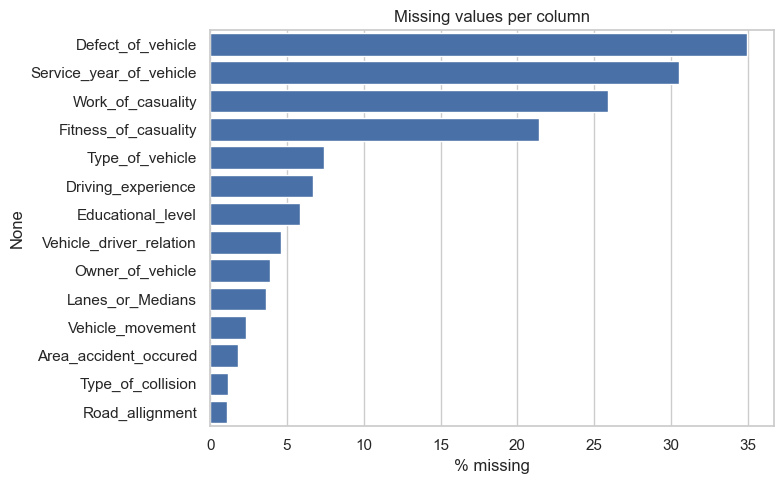

In [8]:
print("Duplicate rows:", data.duplicated().sum())

missing = data.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=missing.values, y=missing.index, color="#3b6fb6", ax=ax)
ax.set_xlabel("% missing"); ax.set_title("Missing values per column")
plt.tight_layout(); plt.show()

**Target distribution.** The classes are heavily imbalanced, so a model that always predicts the majority class already gets a high accuracy. That is our baseline to beat.

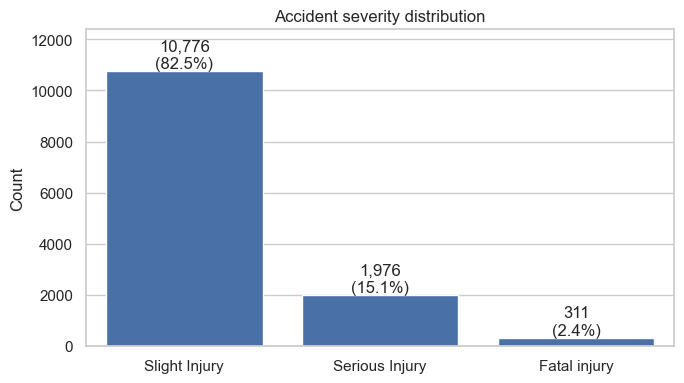

Majority-class baseline accuracy = 82.5%  (accuracy alone is NOT a good metric here)


In [9]:
counts = data[TARGET].value_counts().reindex(CLASS_ORDER)
pct = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, color="#3b6fb6", ax=ax)
for i, (c, p) in enumerate(zip(counts.values, pct.values)):
    ax.text(i, c, f"{c:,}\n({p:.1f}%)", ha="center", va="bottom")
ax.set_title("Accident severity distribution"); ax.set_xlabel(""); ax.set_ylabel("Count")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); plt.show()
print(f"Majority-class baseline accuracy = {pct.max():.1f}%  (accuracy alone is NOT a good metric here)")

## 4. Exploratory data analysis

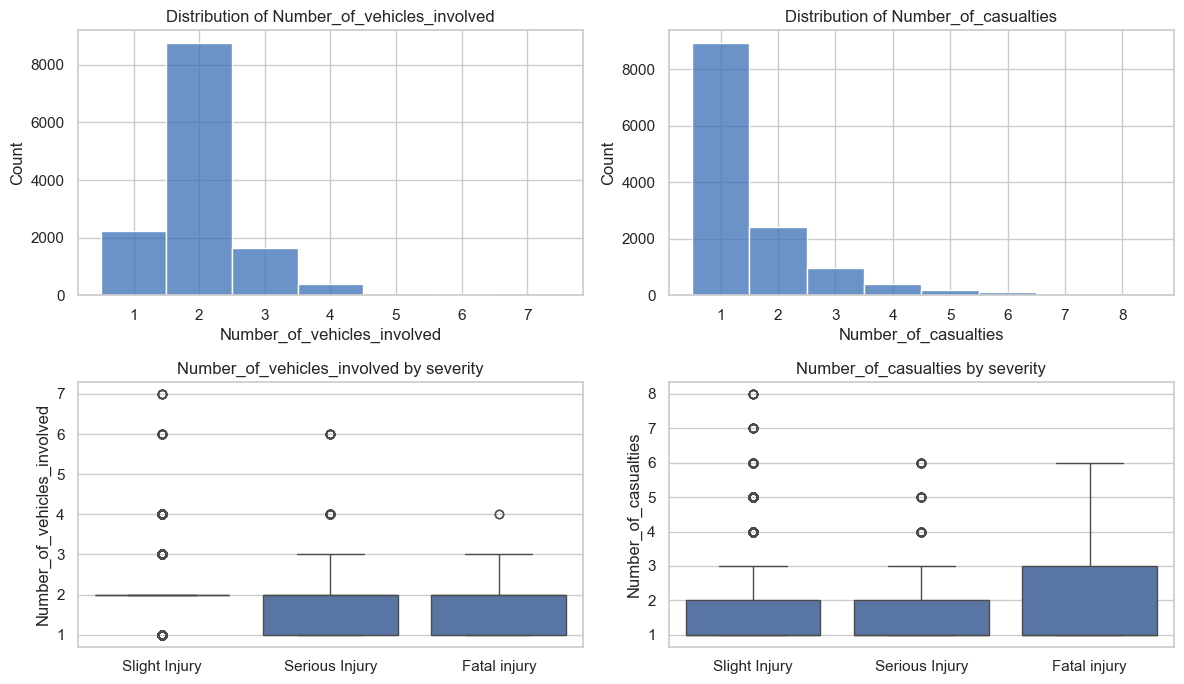

In [10]:
# Numeric features
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, col in enumerate(NUMERIC_COLS):
    sns.histplot(data[col], discrete=True, ax=axes[0, i], color="#3b6fb6")
    axes[0, i].set_title(f"Distribution of {col}")
    sns.boxplot(data=data, x=TARGET, y=col, order=CLASS_ORDER, ax=axes[1, i])
    axes[1, i].set_title(f"{col} by severity"); axes[1, i].set_xlabel("")
plt.tight_layout(); plt.show()

**Share of severe accidents (Serious + Fatal) per category** — more informative than raw counts because it shows risk, not just frequency. Labels show the group size `n`; small groups are noisy.

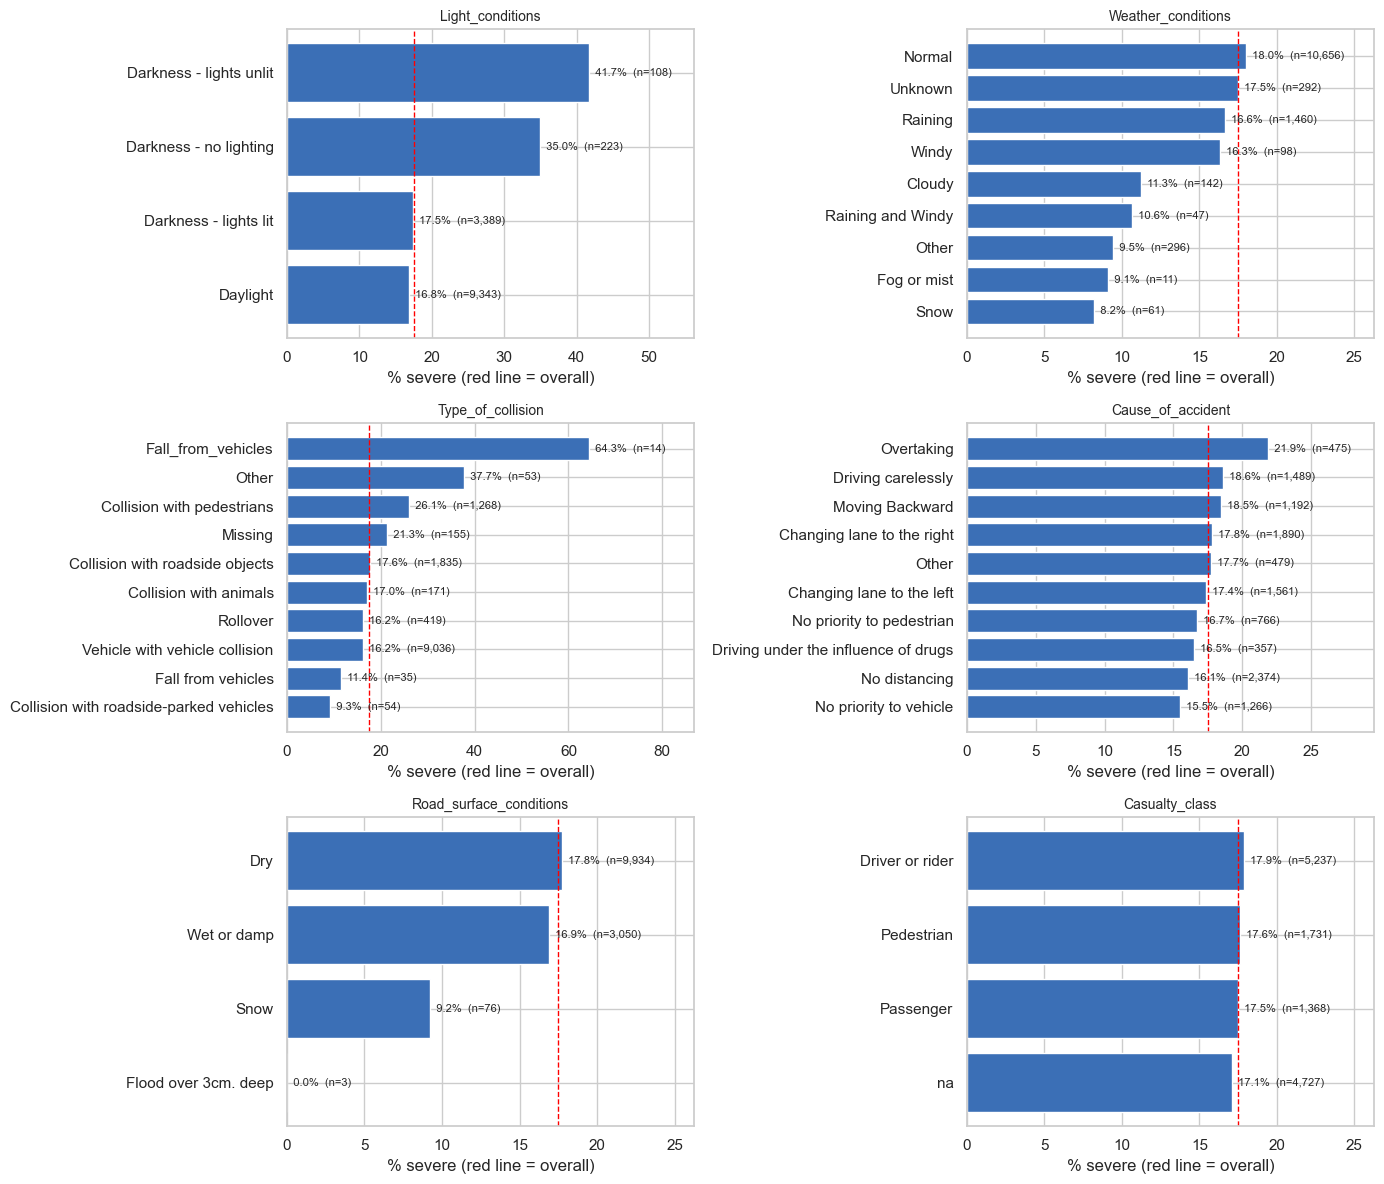

In [11]:
data["_severe"] = data[TARGET].isin(["Serious Injury", "Fatal injury"]).astype(int)
overall = data["_severe"].mean() * 100

def severe_rate_plot(col, top=10, ax=None):
    tmp = data.assign(**{col: data[col].fillna("Missing")})
    g = tmp.groupby(col)["_severe"].agg(["mean", "size"])
    g = g.sort_values("size", ascending=False).head(top).sort_values("mean")
    ax = ax or plt.gca()
    ax.barh(g.index.astype(str), g["mean"] * 100, color="#3b6fb6")
    for y, (m, n) in enumerate(zip(g["mean"] * 100, g["size"])):
        ax.text(m, y, f"  {m:.1f}%  (n={n:,})", va="center", fontsize=8)
    ax.axvline(overall, color="red", ls="--", lw=1)
    ax.set_title(f"{col}", fontsize=10); ax.set_xlabel("% severe (red line = overall)")
    ax.set_xlim(0, max(g["mean"].max() * 100 * 1.35, overall * 1.5))

cols = ["Light_conditions", "Weather_conditions", "Type_of_collision", "Cause_of_accident",
        "Road_surface_conditions", "Casualty_class"]
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for c, ax in zip(cols, axes.ravel()):
    severe_rate_plot(c, ax=ax)
plt.tight_layout(); plt.show()

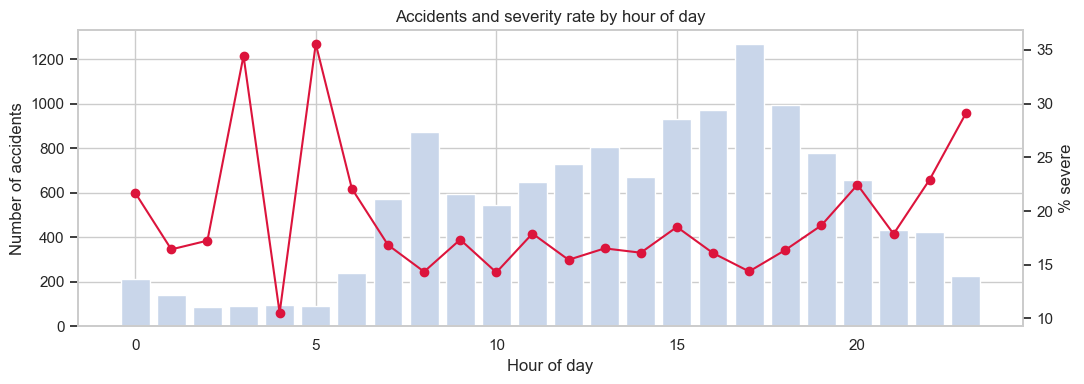

In [12]:
# Hour of day
hour = pd.to_datetime(data["Time"].astype(str), format="mixed", errors="coerce").dt.hour
by_hour = data.assign(hour=hour).groupby("hour")["_severe"].agg(["mean", "size"])
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(by_hour.index, by_hour["size"], color="#c9d6ea", label="accidents")
ax1.set_ylabel("Number of accidents"); ax1.set_xlabel("Hour of day")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["mean"] * 100, color="crimson", marker="o", label="% severe")
ax2.set_ylabel("% severe"); ax2.grid(False)
ax1.set_title("Accidents and severity rate by hour of day")
plt.tight_layout(); plt.show()
data.drop(columns="_severe", inplace=True)

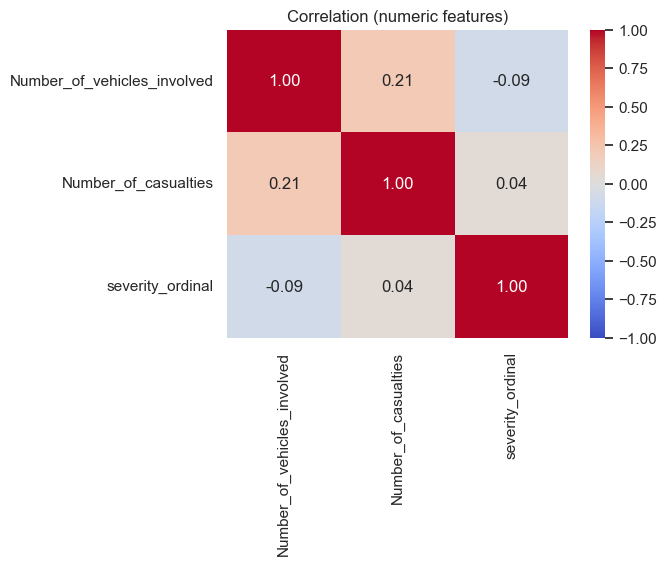

In [13]:
# Correlation between the numeric features and (ordinal) severity
ordinal = data[TARGET].map({c: i for i, c in enumerate(CLASS_ORDER)})
corr = data[NUMERIC_COLS].assign(severity_ordinal=ordinal).corr()
plt.figure(figsize=(5.5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation (numeric features)"); plt.show()

## 5. Preprocessing

* Exact duplicates are dropped.
* Missing categorical values become their **own category** `Missing` (e.g. 35% of `Defect_of_vehicle` is missing — that absence may be informative, and filling it with the mode would invent data). Numeric NaNs → median.
* `Time` → cyclical encoding (`sin`, `cos` of hour) + a night flag, so 23:59 and 00:01 are close.
* One-hot encoding with `handle_unknown="ignore"` so unseen categories in the app cannot crash the model.
* Everything is wrapped in a `ColumnTransformer` **inside** the Pipeline, so it is fitted on training folds only.

In [14]:
def _to_hour(v):
    try:
        p = str(v).strip().split(":")
        h = int(p[0]); m = int(p[1]) if len(p) > 1 else 0; s = int(p[2]) if len(p) > 2 else 0
        return h + m / 60 + s / 3600 if 0 <= h < 24 else np.nan
    except (ValueError, IndexError):
        return np.nan

class CyclicalTime(BaseEstimator, TransformerMixin):
    # 'HH:MM:SS' -> sin/cos of hour-of-day + night flag.
    def fit(self, X, y=None):
        h = self._hours(X)
        self.median_hour_ = float(np.nanmedian(h)) if np.isfinite(h).any() else 12.0
        return self
    @staticmethod
    def _hours(X):
        s = X.iloc[:, 0] if isinstance(X, pd.DataFrame) else pd.Series(np.asarray(X).ravel())
        return s.map(_to_hour).to_numpy(dtype=float)
    def transform(self, X):
        h = self._hours(X); h = np.where(np.isnan(h), self.median_hour_, h)
        a = 2 * np.pi * h / 24
        return np.column_stack([np.sin(a), np.cos(a), ((h >= 20) | (h < 6)).astype(float)])
    def get_feature_names_out(self, input_features=None):
        return np.array(["time_sin", "time_cos", "is_night"])

def build_preprocessor(X, scale_numeric=True):
    cat_cols = [c for c in X.columns if c not in NUMERIC_COLS and c != "Time"]
    num_steps = [("impute", SimpleImputer(strategy="median"))] + ([("scale", StandardScaler())] if scale_numeric else [])
    return ColumnTransformer([
        ("time", CyclicalTime(), ["Time"]),
        ("num", Pipeline(num_steps), NUMERIC_COLS),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=10, sparse_output=False))]),
         cat_cols),
    ], remainder="drop", verbose_feature_names_out=False)

# --- clean + split -------------------------------------------------------------------
df = data.drop_duplicates().reset_index(drop=True)
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].str.strip()

LABELS = [c for c in CLASS_ORDER if c in set(df[TARGET])]
label2id = {l: i for i, l in enumerate(LABELS)}
X, y = df.drop(columns=[TARGET]), df[TARGET].map(label2id).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,}  (stratified)")
print("Train class share:", y_train.value_counts(normalize=True).sort_index().round(3).to_dict())

Train: 10,450 | Test: 2,613  (stratified)
Train class share: {0: 0.825, 1: 0.151, 2: 0.024}


## 6. Why not oversample before cross-validation?

`RandomOverSampler`/naive oversampling duplicates minority rows. If this is done **before** CV, copies of the *same* accident land in both the training and validation fold, so the model "recognises" them. CV scores look great, hyper-parameter search favours deep, memorising trees (`max_depth=None`, `min_samples_leaf=1`) and the real test performance collapses.
The cell below demonstrates it on a Random Forest.

In [15]:
def macro_f1(y_true, y_pred): return f1_score(y_true, y_pred, average="macro", zero_division=0)

prep = build_preprocessor(X_train, scale_numeric=False).fit(X_train)
Xt, Xs = prep.transform(X_train), prep.transform(X_test)

# naive random oversampling of the training set to the majority size
rng = np.random.default_rng(SEED)
n_max = y_train.value_counts().max()
idx = np.concatenate([rng.choice(np.where(y_train.values == k)[0], n_max, replace=True) for k in sorted(y_train.unique())])
Xo, yo = Xt[idx], y_train.values[idx]

rf = RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=-1)
cv = StratifiedKFold(3, shuffle=True, random_state=SEED)

cv_leaky   = cross_val_score(rf, Xo, yo, cv=cv, scoring="f1_macro").mean()
test_leaky = macro_f1(y_test, rf.fit(Xo, yo).predict(Xs))

rf_w = RandomForestClassifier(n_estimators=150, class_weight="balanced", random_state=SEED, n_jobs=-1)
cv_clean   = cross_val_score(rf_w, Xt, y_train, cv=cv, scoring="f1_macro").mean()
test_clean = macro_f1(y_test, rf_w.fit(Xt, y_train).predict(Xs))

pd.DataFrame({"CV macro-F1": [cv_leaky, cv_clean], "Test macro-F1": [test_leaky, test_clean]},
             index=["Oversample BEFORE CV (leaky)", "Class weights (clean)"]).round(3)

,CV macro-F1,Test macro-F1
Oversample BEFORE CV (leaky),0.988,0.393
Class weights (clean),0.304,0.315


A large gap between *CV* and *Test* in the first row = over-optimistic validation. That's why this project uses class weights inside the pipeline.

## 7. Evaluation helpers

In [16]:
def compute_metrics(y_true, y_pred):
    ids = list(range(len(LABELS)))
    rep = classification_report(y_true, y_pred, labels=ids, target_names=LABELS, output_dict=True, zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
            "macro_f1": macro_f1(y_true, y_pred),
            "mcc": matthews_corrcoef(y_true, y_pred),
            "per_class": {l: {k: rep[l][k] for k in ("precision", "recall", "f1-score", "support")} for l in LABELS}}

def plot_confusion(y_true, y_pred, title):
    ids = list(range(len(LABELS)))
    cm = confusion_matrix(y_true, y_pred, labels=ids)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[0])
    axes[0].set_title("Counts")
    sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), annot=True, fmt=".0%", cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS, ax=axes[1], vmin=0, vmax=1)
    axes[1].set_title("Row-normalised (= recall per class)")
    for a in axes: a.set_xlabel("Predicted"); a.set_ylabel("Actual")
    fig.suptitle(title); plt.tight_layout(); plt.show()

results = {}   # name -> dict(cv_macro_f1, test metrics, best_params)
fitted = {}

## 8. Baseline — always predict the majority class

In [17]:
dummy = Pipeline([("prep", build_preprocessor(X_train)), ("clf", DummyClassifier(strategy="most_frequent"))]).fit(X_train, y_train)
results["Majority baseline"] = {"cv_macro_f1": None, "best_params": {}, "test": compute_metrics(y_test, dummy.predict(X_test))}
fitted["Majority baseline"] = dummy
pd.Series({k: v for k, v in results["Majority baseline"]["test"].items() if k != "per_class"}).round(3)

accuracy             0.825
balanced_accuracy    0.333
macro_f1             0.301
mcc                  0.000
dtype: float64

## 9. Machine-learning models (tuned with cross-validation on the training set)

`RandomizedSearchCV`, 5-fold stratified CV, scored by **macro-F1** (treats the 3 classes equally). Class imbalance is handled with `class_weight="balanced"` (Logistic Regression, Random Forest) and balanced `sample_weight` (XGBoost).

In [18]:
N_ITER = 3 if FAST else 20
cv = StratifiedKFold(3 if FAST else 5, shuffle=True, random_state=SEED)
sw_train = compute_sample_weight("balanced", y_train)

candidates = {
    "Logistic Regression": (
        Pipeline([("prep", build_preprocessor(X_train)), ("clf", LogisticRegression(max_iter=3000, class_weight="balanced"))]),
        {"clf__C": loguniform(1e-3, 1e1)}, False),
    "Random Forest": (
        Pipeline([("prep", build_preprocessor(X_train, False)), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=-1))]),
        {"clf__n_estimators": [100] if FAST else [200, 400], "clf__max_depth": [None, 8, 12, 20],
         "clf__min_samples_leaf": [1, 2, 5, 10], "clf__max_features": ["sqrt", "log2", 0.3],
         "clf__class_weight": ["balanced", "balanced_subsample"]}, False),
    "XGBoost": (
        Pipeline([("prep", build_preprocessor(X_train, False)),
                  ("clf", XGBClassifier(objective="multi:softprob", num_class=len(LABELS), eval_metric="mlogloss",
                                        tree_method="hist", random_state=SEED, n_jobs=1))]),
        {"clf__n_estimators": [50] if FAST else [200, 400], "clf__max_depth": [3, 4, 6],
         "clf__learning_rate": [0.03, 0.05, 0.1], "clf__subsample": [0.7, 0.9],
         "clf__colsample_bytree": [0.5, 0.7, 0.9], "clf__min_child_weight": [1, 3, 5],
         "clf__reg_lambda": [1, 5, 10]}, True),
}

for name, (pipe, space, needs_sw) in candidates.items():
    print(f">>> Tuning {name} ...")
    search = RandomizedSearchCV(pipe, space, n_iter=N_ITER, scoring="f1_macro", cv=cv, n_jobs=-1,
                                random_state=SEED, refit=True, error_score="raise")
    search.fit(X_train, y_train, **({"clf__sample_weight": sw_train} if needs_sw else {}))
    fitted[name] = search.best_estimator_
    results[name] = {"cv_macro_f1": float(search.best_score_),
                     "best_params": {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v) for k, v in search.best_params_.items()},
                     "test": compute_metrics(y_test, search.predict(X_test))}
    print(f"    CV macro-F1 = {search.best_score_:.3f}   best params: {results[name]['best_params']}")

>>> Tuning Logistic Regression ...
    CV macro-F1 = 0.370   best params: {'C': 0.03148911647956861}
>>> Tuning Random Forest ...
    CV macro-F1 = 0.529   best params: {'n_estimators': 400, 'min_samples_leaf': 5, 'max_features': 0.3, 'max_depth': 12, 'class_weight': 'balanced'}
>>> Tuning XGBoost ...
    CV macro-F1 = 0.538   best params: {'subsample': 0.9, 'reg_lambda': 1, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.5}


## 10. Neural network (ANN)

A small MLP on the same preprocessed features, with class weights, batch-norm, dropout, L2 and early stopping.
A **validation split carved out of the training set** is used to compare configurations — the test set is not touched until the final report.

In [19]:
try:
    import tensorflow as tf
    from tensorflow import keras
    HAS_TF = True
    tf.keras.utils.set_random_seed(SEED)
except ImportError:
    HAS_TF = False
    print("TensorFlow not installed -> ANN section skipped (pip install tensorflow).")

TensorFlow not installed -> ANN section skipped (pip install tensorflow).


In [20]:
ann_results = []
if HAS_TF:
    X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=SEED)
    ann_prep = build_preprocessor(X_fit).fit(X_fit)
    A_fit, A_val, A_test = (ann_prep.transform(d).astype("float32") for d in (X_fit, X_val, X_test))
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.unique(y_fit), y=y_fit)))

    def build_ann(input_dim, layers, dropout, lr, l2):
        m = keras.Sequential([keras.Input(shape=(input_dim,))])
        for u in layers:
            m.add(keras.layers.Dense(u, kernel_initializer="he_normal", kernel_regularizer=keras.regularizers.l2(l2)))
            m.add(keras.layers.BatchNormalization())
            m.add(keras.layers.LeakyReLU(0.1))
            m.add(keras.layers.Dropout(dropout))
        m.add(keras.layers.Dense(len(LABELS), activation="softmax"))
        m.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        return m

    configs = [
        dict(layers=[128, 64],     dropout=0.30, lr=1e-3, l2=1e-4, batch_size=64),
        dict(layers=[256, 128, 64], dropout=0.40, lr=5e-4, l2=1e-4, batch_size=64),
        dict(layers=[64, 32],      dropout=0.30, lr=1e-3, l2=1e-3, batch_size=128),
        dict(layers=[128, 64, 32], dropout=0.35, lr=5e-4, l2=5e-5, batch_size=64),
    ][: (2 if FAST else 4)]

    for i, cfg in enumerate(configs, 1):
        keras.utils.set_random_seed(SEED)
        hp = {k: cfg[k] for k in ("layers", "dropout", "lr", "l2")}
        model = build_ann(A_fit.shape[1], **hp)
        hist = model.fit(A_fit, y_fit, validation_data=(A_val, y_val), epochs=5 if FAST else 100,
                         batch_size=cfg["batch_size"], class_weight=cw, verbose=0,
                         callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
                                    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6)])
        val_f1 = macro_f1(y_val, model.predict(A_val, verbose=0).argmax(1))
        ann_results.append({"cfg": cfg, "val_macro_f1": val_f1, "model": model, "history": hist.history})
        print(f"Config {i}: {cfg}  ->  val macro-F1 = {val_f1:.3f}  ({len(hist.history['loss'])} epochs)")

    best_ann = max(ann_results, key=lambda r: r["val_macro_f1"])      # selected on VALIDATION, not test
    ann_pred = best_ann["model"].predict(A_test, verbose=0).argmax(1)
    results["ANN (MLP)"] = {"cv_macro_f1": None, "val_macro_f1": best_ann["val_macro_f1"],
                            "best_params": best_ann["cfg"], "test": compute_metrics(y_test, ann_pred)}

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    h = best_ann["history"]
    axes[0].plot(h["loss"], label="train"); axes[0].plot(h["val_loss"], label="validation")
    axes[0].set_title("Best ANN — loss"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(h["accuracy"], label="train"); axes[1].plot(h["val_accuracy"], label="validation")
    axes[1].set_title("Best ANN — accuracy"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

## 11. Model comparison and selection

Deployment candidates are the scikit-learn pipelines (one self-contained artifact, no TensorFlow needed in production). The winner is chosen by **cross-validated macro-F1 on the training set**. Test numbers are reported for transparency, not used to choose.

,CV macro-F1,Val macro-F1 (ANN),Test macro-F1,Test balanced acc,Test accuracy,Test MCC,Recall Serious,Recall Fatal
Majority baseline,NaN,NaN,0.301,0.333,0.825,0.000,0.000,0.000
Logistic Regression,0.370,NaN,0.368,0.518,0.545,0.127,0.385,0.597
Random Forest,0.529,NaN,0.523,0.533,0.772,0.259,0.372,0.371
XGBoost,0.538,NaN,0.525,0.516,0.787,0.270,0.362,0.306



Selected for deployment (best CV macro-F1): XGBoost


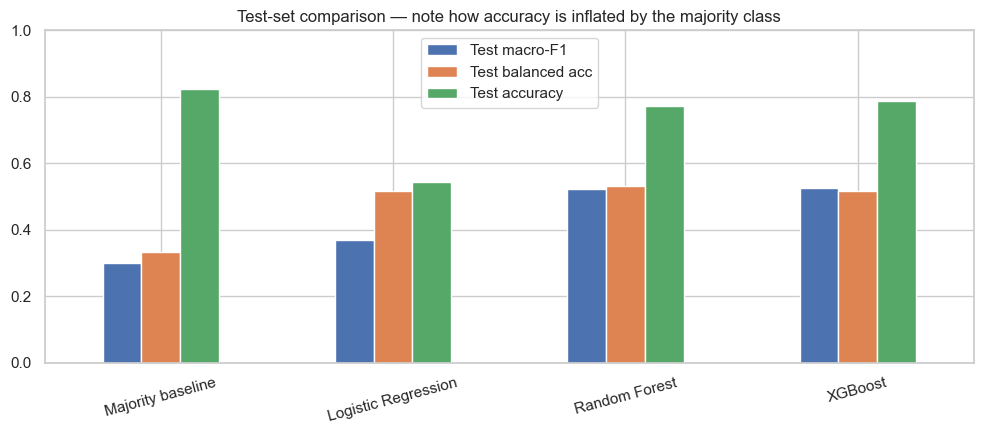

In [21]:
rows = {}
for name, r in results.items():
    t = r["test"]
    rows[name] = {"CV macro-F1": r.get("cv_macro_f1"), "Val macro-F1 (ANN)": r.get("val_macro_f1"),
                  "Test macro-F1": t["macro_f1"], "Test balanced acc": t["balanced_accuracy"],
                  "Test accuracy": t["accuracy"], "Test MCC": t["mcc"],
                  "Recall Serious": t["per_class"].get("Serious Injury", {}).get("recall"),
                  "Recall Fatal": t["per_class"].get("Fatal injury", {}).get("recall")}
comparison = pd.DataFrame(rows).T.astype(float).round(3)
display(comparison)

sk_candidates = [n for n in candidates]
best_name = max(sk_candidates, key=lambda n: results[n]["cv_macro_f1"])
best_pipe = fitted[best_name]
print(f"\nSelected for deployment (best CV macro-F1): {best_name}")

metrics = ["Test macro-F1", "Test balanced acc", "Test accuracy"]
comparison[metrics].plot.bar(figsize=(10, 4.5), rot=15)
plt.ylim(0, 1); plt.title("Test-set comparison — note how accuracy is inflated by the majority class")
plt.tight_layout(); plt.show()

## 11b. Decision-weight tuning (post-processing)

The model outputs class probabilities; plain `argmax` is not necessarily the decision rule that maximises macro-F1 on imbalanced data. We learn one multiplicative weight per class on **out-of-fold training predictions** (never on the test set) and predict `argmax(probability x weight)`. The weights are only kept if they improve the OOF macro-F1 by a meaningful margin.

In [22]:
import itertools
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict

def apply_weights(proba, w): return (np.asarray(proba) * np.asarray(w, dtype=float)).argmax(1)

oof = cross_val_predict(clone(best_pipe), X_train, y_train, cv=cv, method="predict_proba", n_jobs=1,
                        params={"clf__sample_weight": sw_train} if best_name == "XGBoost" else None)
grid = np.unique(np.round(np.concatenate([np.geomspace(0.3, 6, 17), [1.0]]), 4))
oof_before = macro_f1(y_train, oof.argmax(1))
weights, oof_after = np.ones(len(LABELS)), oof_before
for combo in itertools.product(grid, repeat=len(LABELS) - 1):
    w = np.array([1.0, *combo]); sc = macro_f1(y_train, apply_weights(oof, w))
    if sc > oof_after + 1e-12: weights, oof_after = w, sc

use_weights = (oof_after - oof_before) >= 0.005
if not use_weights: weights = np.ones(len(LABELS))
print(f"OOF macro-F1: default {oof_before:.4f} -> tuned {oof_after:.4f} | weights {np.round(weights, 3)} | applied: {use_weights}")

proba_test = best_pipe.predict_proba(X_test)
raw = compute_metrics(y_test, proba_test.argmax(1)); tuned = compute_metrics(y_test, apply_weights(proba_test, weights))
display(pd.DataFrame({"argmax": raw, "tuned decision": tuned}).T[["macro_f1", "balanced_accuracy", "accuracy", "mcc"]].round(3))
display(pd.DataFrame({"argmax": {l: raw["per_class"][l]["recall"] for l in LABELS},
                      "tuned decision": {l: tuned["per_class"][l]["recall"] for l in LABELS}}).T.round(3).rename_axis("recall per class"))

OOF macro-F1: default 0.5384 -> tuned 0.5439 | weights [1.    1.342 1.951] | applied: True


,macro_f1,balanced_accuracy,accuracy,mcc
argmax,0.52452,0.515806,0.787218,0.269924
tuned decision,0.528342,0.559247,0.748948,0.274417


,Slight Injury,Serious Injury,Fatal injury
recall per class,,,
argmax,0.879,0.362,0.306
tuned decision,0.811,0.463,0.403


The trade-off is visible: tuning typically raises precision/accuracy and macro-F1 a little, but can lower the recall of the rare classes. If missing a `Serious`/`Fatal` case is costlier than a false alarm, prefer the raw `argmax` (or weights > 1 for those classes).

## 12. Final evaluation of the selected model (test set, used once)

                precision    recall  f1-score   support

 Slight Injury       0.89      0.81      0.85      2156
Serious Injury       0.33      0.46      0.38       395
  Fatal injury       0.32      0.40      0.35        62

      accuracy                           0.75      2613
     macro avg       0.51      0.56      0.53      2613
  weighted avg       0.79      0.75      0.77      2613



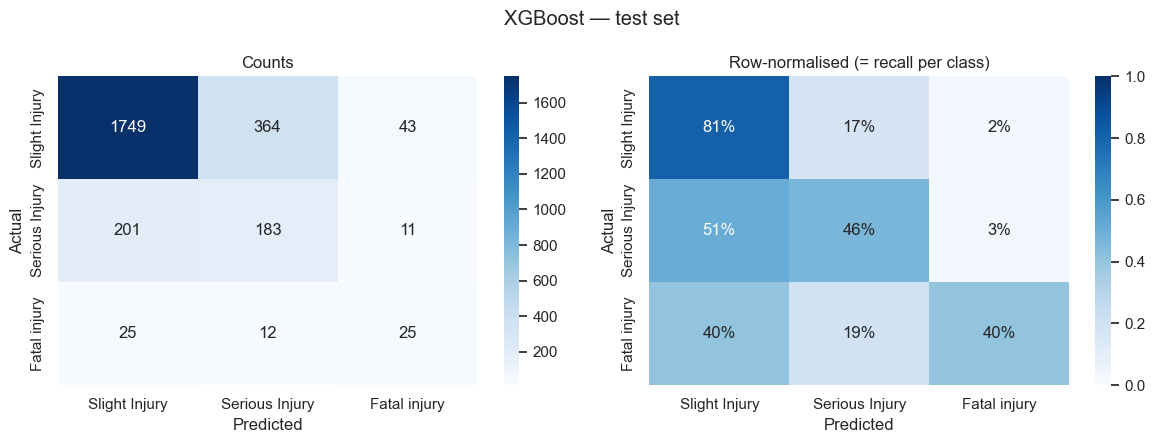

In [23]:
best_pred = apply_weights(best_pipe.predict_proba(X_test), weights)
print(classification_report(y_test, best_pred, target_names=LABELS, zero_division=0))
plot_confusion(y_test, best_pred, f"{best_name} — test set")

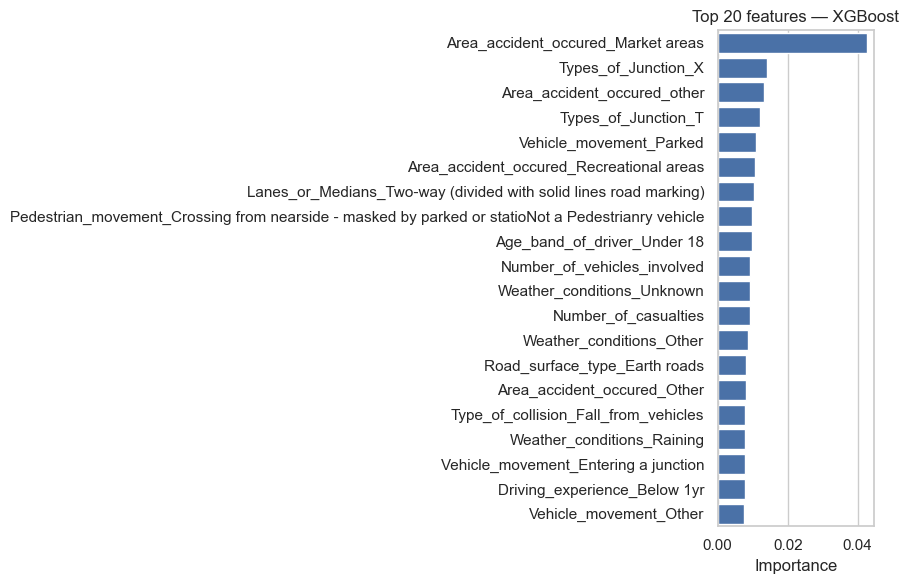

In [24]:
clf = best_pipe.named_steps["clf"]
names = best_pipe.named_steps["prep"].get_feature_names_out()
if hasattr(clf, "feature_importances_"):
    imp = clf.feature_importances_
elif hasattr(clf, "coef_"):
    imp = np.abs(clf.coef_).mean(axis=0)
else:
    imp = None
if imp is not None:
    order = np.argsort(imp)[::-1][:20]
    plt.figure(figsize=(9, 6))
    sns.barplot(x=imp[order], y=np.asarray(names)[order], color="#3b6fb6")
    plt.title(f"Top 20 features — {best_name}"); plt.xlabel("Importance"); plt.tight_layout(); plt.show()

## 13. Export artifacts for deployment
Saves the whole pipeline (preprocessing + model) and a small metadata file used by the Streamlit app.

In [25]:
MODELS_DIR = Path("../models") if Path("../models").exists() else Path("models")
MODELS_DIR.mkdir(exist_ok=True)

cat_cols = [c for c in X_train.columns if c not in NUMERIC_COLS and c != "Time"]
metadata = {
    "model_name": best_name,
    "labels": {str(i): l for i, l in enumerate(LABELS)},
    "input_columns": list(X_train.columns),
    "categorical_options": {c: sorted(df[c].dropna().astype(str).unique().tolist()) for c in cat_cols},
    "numeric_ranges": {c: [int(df[c].min()), int(df[c].max())] for c in NUMERIC_COLS},
    "decision_weights": np.round(weights, 4).tolist(),
    "test_metrics": compute_metrics(y_test, best_pred),
    "trained_at": pd.Timestamp.now("UTC").isoformat(timespec="seconds"),
    "versions": {"scikit-learn": sklearn.__version__},
}
joblib.dump(best_pipe, MODELS_DIR / "model.joblib", compress=3)
(MODELS_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved to", MODELS_DIR.resolve())

Saved to D:\DS Project\traffic-accident-severity\models


**Sanity check — reload and predict one record exactly like the app does:**

In [26]:
loaded = joblib.load(MODELS_DIR / "model.joblib")
sample = X_test.iloc[[0]]
proba = loaded.predict_proba(sample)[0]
print("Actual   :", LABELS[y_test.iloc[0]])
print("Predicted:", LABELS[int(apply_weights(proba.reshape(1, -1), weights)[0])])
print({l: round(float(p), 3) for l, p in zip(LABELS, proba)})
assert np.allclose(proba, best_pipe.predict_proba(sample)[0]), "Reloaded model differs!"

Actual   : Slight Injury
Predicted: Slight Injury
{'Slight Injury': 0.873, 'Serious Injury': 0.121, 'Fatal injury': 0.006}


## 14. Conclusions and limitations

* **Imbalance dominates:** the majority-class baseline already has a high accuracy, so macro-F1, balanced accuracy and per-class recall are the metrics to read. Rare classes (especially `Fatal injury`) remain hard to detect.
* **Honest validation:** preprocessing inside the pipeline + class weights + CV-based selection give results we can trust — they will look lower than the naive-oversampling numbers, but they reflect real generalisation.
* **Limited signal:** the features describe the circumstances of an accident (many are recorded *after* the event, e.g. casualty details), not a rich causal picture. Do not use predictions as a certainty; treat them as a risk indicator.
* **Possible improvements:** probability-threshold tuning for the rare classes, cost-sensitive evaluation (a missed fatal case ≠ a false alarm), SHAP explanations, more data / a time-based split, geospatial features.